# COMP 472 | Decision Tree Classification

**Fall 2026 · Kaggle Project**  
**Method:** Decision Tree implemented from scratch with NumPy  
**Datasets:** Visual object recognition (50 classes) and sentiment analysis (3 classes)

---

### Notebook overview

| Area | Image recognition | Sentiment analysis |
|:--|--:|--:|
| Training examples | 20,000 | 12,000 |
| Validation fraction | 20% | 20% |
| Best recorded Decision Tree validation accuracy | **10.82%** | **49.79%** |
| Best tested criterion | Gini | Gini |
| Best tested maximum depth | 14 | 6 |

*The results above are from the saved experiments in this notebook, not the Kaggle leaderboard. All results use the provided feature vectors only.*

**Sections:** Data preparation · Core algorithm · Initial experiments · Tree depth · Regularization · Gini vs. entropy · Final results · Kaggle submission

## 01 · Data preparation

The notebook uses the same 80/20 stratified train–validation split as the k-NN experiments (`random_state=42`). Put the Kaggle CSV files in the notebook's working directory.

**Required packages:** `numpy`, `pandas`, `matplotlib`, `scikit-learn`. If needed, run `%pip install numpy pandas matplotlib scikit-learn` once in a separate cell.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split

image_train = pd.read_csv("image_train.csv")
sentiment_train = pd.read_csv("sentiment_train.csv")

print("Image dataset:", image_train.shape)
print("Sentiment dataset:", sentiment_train.shape)

print("Missing image labels:", image_train["label"].isna().sum())
print("Missing sentiment labels:", sentiment_train["label"].isna().sum())


Image dataset: (20000, 502)
Sentiment dataset: (12000, 770)
Missing image labels: 0
Missing sentiment labels: 0


### Separate features and labels
`X` contains the numerical representations; `y` contains the correct class labels. IDs are excluded from the model inputs.

In [5]:
X_image = image_train.drop(columns=["id", "label"])
y_image = image_train["label"].astype(int)

X_sentiment = sentiment_train.drop(columns=["id", "label"])
y_sentiment = sentiment_train["label"].astype(int)

print("Image features:", X_image.shape)
print("Image labels:", y_image.shape)

print("Sentiment features:", X_sentiment.shape)
print("Sentiment labels:", y_sentiment.shape)


Image features: (20000, 500)
Image labels: (20000,)
Sentiment features: (12000, 768)
Sentiment labels: (12000,)


### Create training and validation sets
The validation data is held out from training to estimate performance on unseen examples.

In [6]:
X_img_train, X_img_val, y_img_train, y_img_val = train_test_split(
    X_image, y_image,
    test_size=0.2,
    random_state=42,
    stratify=y_image
)

X_sent_train, X_sent_val, y_sent_train, y_sent_val = train_test_split(
    X_sentiment, y_sentiment,
    test_size=0.2,
    random_state=42,
    stratify=y_sentiment
)

print("Image training:", X_img_train.shape)
print("Image validation:", X_img_val.shape)

print("Sentiment training:", X_sent_train.shape)
print("Sentiment validation:", X_sent_val.shape)


Image training: (16000, 500)
Image validation: (4000, 500)
Sentiment training: (9600, 768)
Sentiment validation: (2400, 768)


## 02 · Decision Tree foundations

The classifier chooses a feature and a threshold that reduce class impurity, then recursively builds left and right branches. The small toy example checks each component before applying it to Kaggle data.

### Entropy
Entropy is zero for a pure group and larger when classes are mixed.

In [7]:
def entropy(y):
    counts = np.bincount(y)
    probabilities = counts[counts > 0] / len(y)
    return -np.sum(probabilities * np.log2(probabilities))

print("Pure group:", entropy(np.array([0, 0, 0, 0])))
print("Mixed group:", entropy(np.array([0, 0, 1, 1])))


Pure group: -0.0
Mixed group: 1.0


### Information gain
Information gain measures the reduction in entropy after splitting at a threshold.

In [8]:
def information_gain(y, feature_values, threshold):
    parent_entropy = entropy(y)

    left_mask = feature_values <= threshold
    right_mask = feature_values > threshold

    y_left = y[left_mask]
    y_right = y[right_mask]

    if len(y_left) == 0 or len(y_right) == 0:
        return 0

    n = len(y)

    child_entropy = (
        (len(y_left) / n) * entropy(y_left)
        + (len(y_right) / n) * entropy(y_right)
    )

    return parent_entropy - child_entropy


y_test = np.array([0, 0, 1, 1])
feature_test = np.array([0.1, 0.2, 0.8, 0.9])

gain = information_gain(y_test, feature_test, 0.5)

print("Information Gain:", gain)


Information Gain: 1.0


### Search candidate splits
This initial version evaluates a small set of quantile thresholds per feature.

In [9]:
def best_split(X, y, n_thresholds=9):
    X = np.asarray(X)
    y = np.asarray(y, dtype=int)

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in range(X.shape[1]):
        values = X[:, feature]

        thresholds = np.unique(
            np.quantile(
                values,
                np.linspace(0.1, 0.9, n_thresholds)
            )
        )

        for threshold in thresholds:
            gain = information_gain(y, values, threshold)

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold, best_gain


X_test = np.array([
    [0.1, 0.6],
    [0.2, 0.2],
    [0.8, 0.1],
    [0.9, 0.9]
])

y_test = np.array([0, 0, 1, 1])

feature, threshold, gain = best_split(X_test, y_test)

print("Best feature:", feature)
print("Best threshold:", threshold)
print("Information Gain:", gain)


Best feature: 0
Best threshold: 0.3200000000000001
Information Gain: 1.0


### Build a recursive tree
Each terminal node stores the most frequent class in that part of the training data.

In [10]:
def build_tree(X, y, depth=0, max_depth=3):
    X = np.asarray(X)
    y = np.asarray(y, dtype=int)

    majority_class = np.bincount(y).argmax()

    if depth >= max_depth or len(np.unique(y)) == 1:
        return {"label": majority_class}

    feature, threshold, gain = best_split(X, y)

    if feature is None or gain <= 0:
        return {"label": majority_class}

    left_mask = X[:, feature] <= threshold
    right_mask = ~left_mask

    left_tree = build_tree(
        X[left_mask], y[left_mask], depth + 1, max_depth
    )

    right_tree = build_tree(
        X[right_mask], y[right_mask], depth + 1, max_depth
    )

    return {
        "feature": feature,
        "threshold": threshold,
        "left": left_tree,
        "right": right_tree
    }


tree = build_tree(X_test, y_test)

print(tree)


{'feature': 0, 'threshold': np.float64(0.3200000000000001), 'left': {'label': np.int64(0)}, 'right': {'label': np.int64(1)}}


### Predict labels
For each sample, follow the feature tests until a terminal node is reached.

In [11]:
def predict_one(tree, x):
    if "label" in tree:
        return tree["label"]

    feature = tree["feature"]
    threshold = tree["threshold"]

    if x[feature] <= threshold:
        return predict_one(tree["left"], x)
    else:
        return predict_one(tree["right"], x)


def predict_tree(tree, X):
    X = np.asarray(X)
    return np.array([predict_one(tree, x) for x in X])


predictions = predict_tree(tree, X_test)

print("Predictions:", predictions)
print("Correct labels:", y_test)
print("Accuracy:", np.mean(predictions == y_test) * 100, "%")


Predictions: [0 0 1 1]
Correct labels: [0 0 1 1]
Accuracy: 100.0 %


## 03 · Image recognition — initial experiments

These are exploratory runs to check that the implementation works and to examine how training-set size and tree depth affect accuracy. **The first two runs use the initial, slower split-search implementation.**

### Pilot: 1,000 examples, depth 3

In [12]:
X_small, _, y_small, _ = train_test_split(
    X_img_train,
    y_img_train,
    train_size=1000,
    random_state=42,
    stratify=y_img_train
)

image_tree = build_tree(
    X_small.to_numpy(),
    y_small.to_numpy(),
    max_depth=3
)

predictions = predict_tree(
    image_tree,
    X_img_val.to_numpy()
)

accuracy = np.mean(
    predictions == y_img_val.to_numpy()
)

print(f"Image Validation Accuracy: {accuracy * 100:.2f}%")


Image Validation Accuracy: 3.75%


### Pilot: 1,000 examples, depth 6

In [13]:
image_tree = build_tree(
    X_small.to_numpy(),
    y_small.to_numpy(),
    max_depth=6
)

train_predictions = predict_tree(
    image_tree,
    X_small.to_numpy()
)

val_predictions = predict_tree(
    image_tree,
    X_img_val.to_numpy()
)

train_accuracy = np.mean(
    train_predictions == y_small.to_numpy()
)

val_accuracy = np.mean(
    val_predictions == y_img_val.to_numpy()
)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")


Training Accuracy: 18.60%
Validation Accuracy: 3.38%


### Faster split evaluation
The next function evaluates candidate thresholds in batches using class counts and vectorized NumPy operations. Subsequent experiments use this version.

In [14]:
def entropy_counts(counts):
    counts = np.asarray(counts, dtype=float)
    total = counts.sum(axis=-1, keepdims=True)

    probabilities = np.divide(
        counts,
        total,
        out=np.zeros_like(counts),
        where=total > 0
    )

    return -np.sum(
        probabilities * np.log2(np.maximum(probabilities, 1e-12)),
        axis=-1
    )


def best_split(X, y, n_thresholds=9, min_samples_leaf=5):
    X = np.asarray(X)
    y = np.asarray(y, dtype=int)

    n_samples, n_features = X.shape
    n_classes = int(y.max()) + 1

    parent_counts = np.bincount(y, minlength=n_classes)
    parent_entropy = entropy_counts(parent_counts)

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in range(n_features):
        values = X[:, feature]

        thresholds = np.unique(
            np.quantile(
                values,
                np.linspace(0.1, 0.9, n_thresholds)
            )
        )

        bins = np.searchsorted(
            thresholds, values, side="left"
        )

        counts = np.bincount(
            bins * n_classes + y,
            minlength=(len(thresholds) + 1) * n_classes
        ).reshape(-1, n_classes)

        left_counts = np.cumsum(counts, axis=0)[:-1]
        right_counts = parent_counts - left_counts

        n_left = left_counts.sum(axis=1)
        n_right = n_samples - n_left

        valid = (
            (n_left >= min_samples_leaf) &
            (n_right >= min_samples_leaf)
        )

        if not valid.any():
            continue

        gains = (
            parent_entropy
            - (n_left / n_samples) * entropy_counts(left_counts)
            - (n_right / n_samples) * entropy_counts(right_counts)
        )

        gains[~valid] = -np.inf

        index = np.argmax(gains)

        if gains[index] > best_gain:
            best_gain = float(gains[index])
            best_feature = feature
            best_threshold = thresholds[index]

    return best_feature, best_threshold, best_gain


print("Optimized best_split function ready!")


Optimized best_split function ready!


### Increase training data to 4,000 examples

In [15]:
X_medium, _, y_medium, _ = train_test_split(
    X_img_train,
    y_img_train,
    train_size=4000,
    random_state=42,
    stratify=y_img_train
)

start = time.time()

image_tree = build_tree(
    X_medium.to_numpy(),
    y_medium.to_numpy(),
    max_depth=6
)

training_time = time.time() - start

train_predictions = predict_tree(
    image_tree,
    X_medium.to_numpy()
)

val_predictions = predict_tree(
    image_tree,
    X_img_val.to_numpy()
)

train_accuracy = np.mean(
    train_predictions == y_medium.to_numpy()
)

val_accuracy = np.mean(
    val_predictions == y_img_val.to_numpy()
)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Training Time: {training_time:.2f} seconds")


Training Accuracy: 11.72%
Validation Accuracy: 7.27%
Training Time: 4.96 seconds


### Use the full training split: 16,000 examples

In [16]:
start = time.time()

image_tree = build_tree(
    X_img_train.to_numpy(),
    y_img_train.to_numpy(),
    max_depth=6
)

training_time = time.time() - start

train_predictions = predict_tree(
    image_tree,
    X_img_train.to_numpy()
)

val_predictions = predict_tree(
    image_tree,
    X_img_val.to_numpy()
)

train_accuracy = np.mean(
    train_predictions == y_img_train.to_numpy()
)

val_accuracy = np.mean(
    val_predictions == y_img_val.to_numpy()
)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Training Time: {training_time:.2f} seconds")


Training Accuracy: 9.61%
Validation Accuracy: 8.33%
Training Time: 6.03 seconds


## 04 · Maximum-depth experiments

A shallow tree may underfit. A deeper tree can learn more detailed patterns, but may also overfit. Compare **training vs. validation accuracy** rather than choosing depth based on training performance alone.

### Image recognition — depth sweep

In [17]:
depths = [3, 6, 10, 14]
results = []

for depth in depths:
    start = time.time()

    tree = build_tree(
        X_img_train.to_numpy(),
        y_img_train.to_numpy(),
        max_depth=depth
    )

    train_pred = predict_tree(
        tree, X_img_train.to_numpy()
    )

    val_pred = predict_tree(
        tree, X_img_val.to_numpy()
    )

    train_acc = np.mean(
        train_pred == y_img_train.to_numpy()
    ) * 100

    val_acc = np.mean(
        val_pred == y_img_val.to_numpy()
    ) * 100

    elapsed = time.time() - start

    results.append({
        "Depth": depth,
        "Training Accuracy (%)": train_acc,
        "Validation Accuracy (%)": val_acc,
        "Time (s)": elapsed
    })

    print(
        f"Depth {depth}: "
        f"Training = {train_acc:.2f}%, "
        f"Validation = {val_acc:.2f}%"
    )

depth_results = pd.DataFrame(results)
display(depth_results)


Depth 3: Training = 5.55%, Validation = 5.73%
Depth 6: Training = 9.61%, Validation = 8.33%
Depth 10: Training = 16.84%, Validation = 9.40%
Depth 14: Training = 27.30%, Validation = 10.12%


,Depth,Training Accuracy (%),Validation Accuracy (%),Time (s)
0,3,5.55000,5.725,1.195087
1,6,9.61250,8.325,6.153902
2,10,16.84375,9.400,37.878302
3,14,27.30000,10.125,115.405169


### Image recognition — accuracy curve

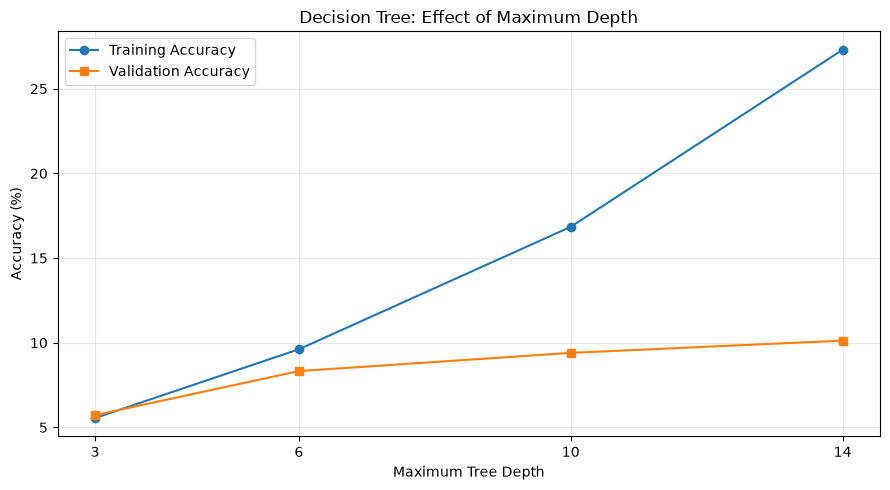

In [18]:
plt.figure(figsize=(9, 5))

plt.plot(
    depth_results["Depth"],
    depth_results["Training Accuracy (%)"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results["Depth"],
    depth_results["Validation Accuracy (%)"],
    marker="s",
    label="Validation Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy (%)")
plt.title("Decision Tree: Effect of Maximum Depth")

plt.xticks(depths)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Sentiment analysis — depth sweep

In [19]:
depths = [3, 6, 10, 14]
sentiment_results = []

for depth in depths:
    start = time.time()

    tree = build_tree(
        X_sent_train.to_numpy(),
        y_sent_train.to_numpy(),
        max_depth=depth
    )

    train_pred = predict_tree(
        tree, X_sent_train.to_numpy()
    )

    val_pred = predict_tree(
        tree, X_sent_val.to_numpy()
    )

    train_acc = np.mean(
        train_pred == y_sent_train.to_numpy()
    ) * 100

    val_acc = np.mean(
        val_pred == y_sent_val.to_numpy()
    ) * 100

    elapsed = time.time() - start

    sentiment_results.append({
        "Depth": depth,
        "Training Accuracy (%)": train_acc,
        "Validation Accuracy (%)": val_acc,
        "Time (s)": elapsed
    })

    print(
        f"Depth {depth}: "
        f"Training = {train_acc:.2f}%, "
        f"Validation = {val_acc:.2f}%"
    )

sentiment_depth_results = pd.DataFrame(sentiment_results)
display(sentiment_depth_results)


Depth 3: Training = 46.29%, Validation = 45.21%
Depth 6: Training = 54.67%, Validation = 47.79%
Depth 10: Training = 76.44%, Validation = 46.04%
Depth 14: Training = 89.68%, Validation = 45.33%


,Depth,Training Accuracy (%),Validation Accuracy (%),Time (s)
0,3,46.291667,45.208333,2.112921
1,6,54.666667,47.791667,10.169368
2,10,76.437500,46.041667,85.051672
3,14,89.677083,45.333333,167.466263


### Sentiment analysis — accuracy curve

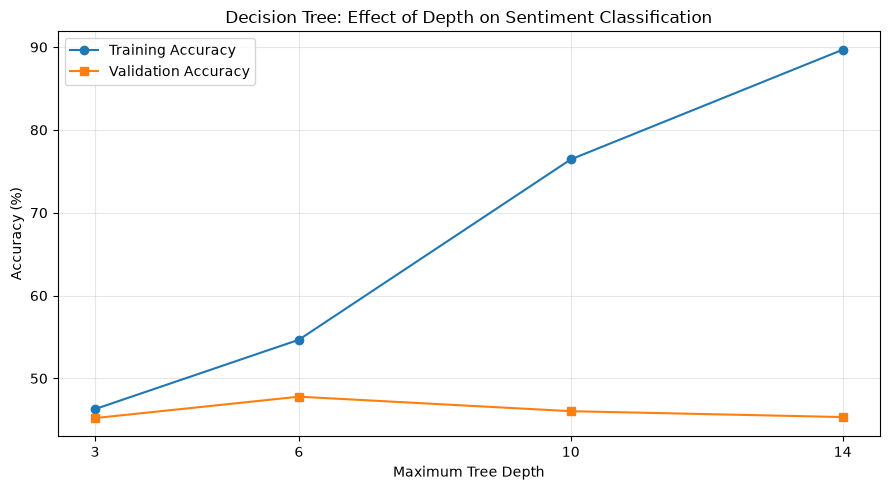

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    sentiment_depth_results["Depth"],
    sentiment_depth_results["Training Accuracy (%)"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    sentiment_depth_results["Depth"],
    sentiment_depth_results["Validation Accuracy (%)"],
    marker="s",
    label="Validation Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy (%)")
plt.title("Decision Tree: Effect of Depth on Sentiment Classification")

plt.xticks([3, 6, 10, 14])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Observation:** In the saved sentiment experiment, validation accuracy peaks at depth 6 (47.79%) while training accuracy keeps rising at greater depths. This is evidence of overfitting for deeper trees.

## 05 · Control tree complexity

Test minimum leaf size and minimum split size to limit excessive branching. These experiments use sentiment features and the entropy criterion.

### Add minimum-leaf and minimum-split constraints

In [21]:
def build_tree(X, y, depth=0, max_depth=6,
               min_samples_leaf=5, min_samples_split=20):
    X = np.asarray(X)
    y = np.asarray(y, dtype=int)

    majority_class = np.bincount(y).argmax()

    if (
        depth >= max_depth
        or len(np.unique(y)) == 1
        or len(y) < min_samples_split
        or len(y) < 2 * min_samples_leaf
    ):
        return {"label": majority_class}

    feature, threshold, gain = best_split(
        X, y, min_samples_leaf=min_samples_leaf
    )

    if feature is None or gain <= 0:
        return {"label": majority_class}

    left_mask = X[:, feature] <= threshold
    right_mask = ~left_mask

    return {
        "feature": feature,
        "threshold": threshold,
        "left": build_tree(
            X[left_mask], y[left_mask],
            depth + 1, max_depth,
            min_samples_leaf, min_samples_split
        ),
        "right": build_tree(
            X[right_mask], y[right_mask],
            depth + 1, max_depth,
            min_samples_leaf, min_samples_split
        )
    }


### Sentiment — minimum samples per leaf

In [22]:
leaf_sizes = [5, 20, 50, 100]
leaf_results = []

for leaf_size in leaf_sizes:
    tree = build_tree(
        X_sent_train.to_numpy(),
        y_sent_train.to_numpy(),
        max_depth=6,
        min_samples_leaf=leaf_size
    )

    train_pred = predict_tree(
        tree, X_sent_train.to_numpy()
    )

    val_pred = predict_tree(
        tree, X_sent_val.to_numpy()
    )

    train_acc = np.mean(
        train_pred == y_sent_train.to_numpy()
    ) * 100

    val_acc = np.mean(
        val_pred == y_sent_val.to_numpy()
    ) * 100

    leaf_results.append({
        "Min Leaf Size": leaf_size,
        "Training Accuracy (%)": train_acc,
        "Validation Accuracy (%)": val_acc
    })

    print(
        f"Leaf Size {leaf_size}: "
        f"Training = {train_acc:.2f}%, "
        f"Validation = {val_acc:.2f}%"
    )

leaf_results_df = pd.DataFrame(leaf_results)
display(leaf_results_df)


Leaf Size 5: Training = 54.67%, Validation = 47.79%
Leaf Size 20: Training = 54.70%, Validation = 47.79%
Leaf Size 50: Training = 54.23%, Validation = 48.17%
Leaf Size 100: Training = 53.84%, Validation = 47.79%


,Min Leaf Size,Training Accuracy (%),Validation Accuracy (%)
0,5,54.666667,47.791667
1,20,54.697917,47.791667
2,50,54.229167,48.166667
3,100,53.843750,47.791667


### Sentiment — minimum samples required to split

In [23]:
split_sizes = [20, 100, 300, 600]
split_results = []

for split_size in split_sizes:
    tree = build_tree(
        X_sent_train.to_numpy(),
        y_sent_train.to_numpy(),
        max_depth=6,
        min_samples_leaf=50,
        min_samples_split=split_size
    )

    train_pred = predict_tree(
        tree, X_sent_train.to_numpy()
    )

    val_pred = predict_tree(
        tree, X_sent_val.to_numpy()
    )

    train_acc = np.mean(
        train_pred == y_sent_train.to_numpy()
    ) * 100

    val_acc = np.mean(
        val_pred == y_sent_val.to_numpy()
    ) * 100

    split_results.append({
        "Min Split Size": split_size,
        "Training Accuracy (%)": train_acc,
        "Validation Accuracy (%)": val_acc
    })

    print(
        f"Split Size {split_size}: "
        f"Training = {train_acc:.2f}%, "
        f"Validation = {val_acc:.2f}%"
    )

split_results_df = pd.DataFrame(split_results)
display(split_results_df)


Split Size 20: Training = 54.23%, Validation = 48.17%
Split Size 100: Training = 54.23%, Validation = 48.17%
Split Size 300: Training = 52.52%, Validation = 47.83%
Split Size 600: Training = 50.69%, Validation = 47.42%


,Min Split Size,Training Accuracy (%),Validation Accuracy (%)
0,20,54.229167,48.166667
1,100,54.229167,48.166667
2,300,52.520833,47.833333
3,600,50.687500,47.416667


## 06 · Splitting criterion — entropy vs. Gini

Both criteria measure impurity, but can select different feature thresholds. Hold the other hyperparameters fixed to compare them fairly.

### Gini impurity

In [24]:
def gini_counts(counts):
    counts = np.asarray(counts, dtype=float)

    total = counts.sum(axis=-1, keepdims=True)

    probabilities = np.divide(
        counts,
        total,
        out=np.zeros_like(counts),
        where=total > 0
    )

    return np.sum(
        probabilities * (1 - probabilities),
        axis=-1
    )


print("Pure group:", gini_counts([10, 0]))
print("Mixed group:", gini_counts([5, 5]))


Pure group: 0.0
Mixed group: 0.5


### Enable both impurity criteria in split search

In [25]:
def best_split(X, y, n_thresholds=9, min_samples_leaf=5,
               criterion="entropy"):

    X = np.asarray(X)
    y = np.asarray(y, dtype=int)

    n_samples, n_features = X.shape
    n_classes = int(y.max()) + 1

    impurity_function = {
        "entropy": entropy_counts,
        "gini": gini_counts
    }[criterion]

    parent_counts = np.bincount(y, minlength=n_classes)
    parent_impurity = impurity_function(parent_counts)

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in range(n_features):
        values = X[:, feature]

        thresholds = np.unique(
            np.quantile(
                values,
                np.linspace(0.1, 0.9, n_thresholds)
            )
        )

        bins = np.searchsorted(
            thresholds, values, side="left"
        )

        counts = np.bincount(
            bins * n_classes + y,
            minlength=(len(thresholds) + 1) * n_classes
        ).reshape(-1, n_classes)

        left_counts = np.cumsum(counts, axis=0)[:-1]
        right_counts = parent_counts - left_counts

        n_left = left_counts.sum(axis=1)
        n_right = n_samples - n_left

        valid = (
            (n_left >= min_samples_leaf) &
            (n_right >= min_samples_leaf)
        )

        if not valid.any():
            continue

        gains = (
            parent_impurity
            - (n_left / n_samples) * impurity_function(left_counts)
            - (n_right / n_samples) * impurity_function(right_counts)
        )

        gains[~valid] = -np.inf

        index = np.argmax(gains)

        if gains[index] > best_gain:
            best_gain = float(gains[index])
            best_feature = feature
            best_threshold = thresholds[index]

    return best_feature, best_threshold, best_gain


toy_X = np.array([[0.1], [0.2], [0.8], [0.9]])
toy_y = np.array([0, 0, 1, 1])

print("Entropy:", best_split(toy_X, toy_y, min_samples_leaf=1,
                             criterion="entropy"))

print("Gini:", best_split(toy_X, toy_y, min_samples_leaf=1,
                          criterion="gini"))


Entropy: (0, np.float64(0.3200000000000001), 1.0)
Gini: (0, np.float64(0.3200000000000001), 0.5)


### Enable criterion selection when growing the tree

In [26]:
def build_tree(X, y, depth=0, max_depth=6,
               min_samples_leaf=5, min_samples_split=20,
               criterion="entropy"):

    X = np.asarray(X)
    y = np.asarray(y, dtype=int)

    majority_class = np.bincount(y).argmax()

    if (
        depth >= max_depth
        or len(np.unique(y)) == 1
        or len(y) < min_samples_split
        or len(y) < 2 * min_samples_leaf
    ):
        return {"label": majority_class}

    feature, threshold, gain = best_split(
        X,
        y,
        min_samples_leaf=min_samples_leaf,
        criterion=criterion
    )

    if feature is None or gain <= 0:
        return {"label": majority_class}

    left_mask = X[:, feature] <= threshold
    right_mask = ~left_mask

    return {
        "feature": feature,
        "threshold": threshold,
        "left": build_tree(
            X[left_mask],
            y[left_mask],
            depth=depth + 1,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            min_samples_split=min_samples_split,
            criterion=criterion
        ),
        "right": build_tree(
            X[right_mask],
            y[right_mask],
            depth=depth + 1,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            min_samples_split=min_samples_split,
            criterion=criterion
        )
    }


print("Decision Tree updated successfully!")


Decision Tree updated successfully!


### Sentiment — criterion comparison

In [27]:
criterion_results = []

for criterion in ["entropy", "gini"]:
    start = time.time()

    tree = build_tree(
        X_sent_train.to_numpy(),
        y_sent_train.to_numpy(),
        max_depth=6,
        min_samples_leaf=50,
        min_samples_split=20,
        criterion=criterion
    )

    train_pred = predict_tree(
        tree, X_sent_train.to_numpy()
    )

    val_pred = predict_tree(
        tree, X_sent_val.to_numpy()
    )

    train_acc = np.mean(
        train_pred == y_sent_train.to_numpy()
    ) * 100

    val_acc = np.mean(
        val_pred == y_sent_val.to_numpy()
    ) * 100

    criterion_results.append({
        "Criterion": criterion,
        "Training Accuracy (%)": train_acc,
        "Validation Accuracy (%)": val_acc,
        "Time (s)": time.time() - start
    })

    print(
        f"{criterion}: "
        f"Training = {train_acc:.2f}%, "
        f"Validation = {val_acc:.2f}%"
    )

criterion_results_df = pd.DataFrame(criterion_results)
display(criterion_results_df)


entropy: Training = 54.23%, Validation = 48.17%
gini: Training = 55.21%, Validation = 49.79%


,Criterion,Training Accuracy (%),Validation Accuracy (%),Time (s)
0,entropy,54.229167,48.166667,9.830544
1,gini,55.208333,49.791667,10.163105


### Image recognition — criterion comparison

In [28]:
image_criterion_results = []

for criterion in ["entropy", "gini"]:
    start = time.time()

    tree = build_tree(
        X_img_train.to_numpy(),
        y_img_train.to_numpy(),
        max_depth=14,
        min_samples_leaf=5,
        min_samples_split=20,
        criterion=criterion
    )

    train_pred = predict_tree(
        tree, X_img_train.to_numpy()
    )

    val_pred = predict_tree(
        tree, X_img_val.to_numpy()
    )

    train_acc = np.mean(
        train_pred == y_img_train.to_numpy()
    ) * 100

    val_acc = np.mean(
        val_pred == y_img_val.to_numpy()
    ) * 100

    image_criterion_results.append({
        "Criterion": criterion,
        "Training Accuracy (%)": train_acc,
        "Validation Accuracy (%)": val_acc,
        "Time (s)": time.time() - start
    })

    print(
        f"{criterion}: "
        f"Training = {train_acc:.2f}%, "
        f"Validation = {val_acc:.2f}%"
    )

image_criterion_results_df = pd.DataFrame(
    image_criterion_results
)

display(image_criterion_results_df)


entropy: Training = 22.66%, Validation = 10.03%
gini: Training = 19.36%, Validation = 10.82%


,Criterion,Training Accuracy (%),Validation Accuracy (%),Time (s)
0,entropy,22.6625,10.025,54.660135
1,gini,19.3625,10.825,35.793429


## 07 · Final validation results

The experiments above recorded **10.82% image accuracy** and **49.79% sentiment accuracy** with Gini. These results are from validation splits, not hidden Kaggle labels.

| Dataset | Criterion | Depth | Min. leaf | Min. split | Validation accuracy |
|:--|:--|--:|--:|--:|--:|
| Image | Gini | 14 | 5 | 20 | **10.82%** |
| Sentiment | Gini | 6 | 50 | 20 | **49.79%** |

These are the best settings tested in this notebook. The single Decision Tree performs substantially worse than the previously tested k-NN classifier on image features, which is an important result for the report.

In [29]:
final_results = pd.concat([
    image_criterion_results_df.assign(Dataset="Image"),
    criterion_results_df.assign(Dataset="Sentiment")
], ignore_index=True)

final_results = final_results[
    [
        "Dataset",
        "Criterion",
        "Training Accuracy (%)",
        "Validation Accuracy (%)",
        "Time (s)"
    ]
]

display(final_results)

final_results.to_csv(
    "decision_tree_results.csv",
    index=False
)

print("Decision Tree results saved!")


,Dataset,Criterion,Training Accuracy (%),Validation Accuracy (%),Time (s)
0,Image,entropy,22.662500,10.025000,54.660135
1,Image,gini,19.362500,10.825000,35.793429
2,Sentiment,entropy,54.229167,48.166667,9.830544
3,Sentiment,gini,55.208333,49.791667,10.163105


Decision Tree results saved!


## 08 · Kaggle submission (optional)

Run this cell **after** the experiments if you want to produce a Decision Tree submission. The models are retrained on all labeled examples, and the final file is aligned to `sample_submission.csv` using sample IDs, not row order.

The file `submission.csv` contains exactly **10,000 predictions** with columns `id,label`. This is the Kaggle upload file; `decision_tree_results.csv` is only for experimental reporting.

*Note:* The earlier k-NN model has higher validation accuracy on both tasks, so this Decision Tree submission is more useful for comparison than as the strongest final entry.

In [ ]:
image_test = pd.read_csv("image_test.csv")
sentiment_test = pd.read_csv("sentiment_test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

final_image_tree = build_tree(
    X_image.to_numpy(), y_image.to_numpy(),
    max_depth=14, min_samples_leaf=5,
    min_samples_split=20, criterion="gini"
)

final_sentiment_tree = build_tree(
    X_sentiment.to_numpy(), y_sentiment.to_numpy(),
    max_depth=6, min_samples_leaf=50,
    min_samples_split=20, criterion="gini"
)

image_predictions = predict_tree(
    final_image_tree, image_test[X_image.columns].to_numpy()
)
sentiment_predictions = predict_tree(
    final_sentiment_tree, sentiment_test[X_sentiment.columns].to_numpy()
)

predictions = pd.concat([
    pd.DataFrame({"id": image_test["id"], "label": image_predictions}),
    pd.DataFrame({"id": sentiment_test["id"], "label": sentiment_predictions})
], ignore_index=True)

submission = sample_submission[["id"]].merge(
    predictions, on="id", how="left", validate="one_to_one"
)

assert len(submission) == 10000
assert submission["id"].is_unique
assert submission["label"].notna().all()

submission["label"] = submission["label"].astype(int)

image_rows = submission["id"].str.startswith("img_")
sentiment_rows = submission["id"].str.startswith("text_")

assert image_rows.sum() == 5000
assert sentiment_rows.sum() == 5000
assert submission.loc[image_rows, "label"].between(0, 49).all()
assert submission.loc[sentiment_rows, "label"].between(0, 2).all()

submission.to_csv("submission.csv", index=False)

print("Saved submission.csv with", len(submission), "predictions")
display(submission.head())